# # Daily Extremes Timeseries from 2D Fields (25km IAF JRA55-do, ACCESS-OM3)

This notebook uses daily extreme values derived from 2D fields, using the [dev-MC_25km_jra_iaf configuration](https://github.com/ACCESS-NRI/access-om3-configs/tree/efc6d1f913b453898aa82fa40dbe133560c6bad2) of ACCESS-OM3.

In [1]:
#parameters

# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
esm_file='/g/data/tm70/ml0072/COMMON/git_repos/access-experiment-generator/2025.02.000/c1_25km_iaf_check-max-min-daily-only/perturb_1/MC_25km_jra_iaf/archive/experiment_datastore.json'
esm_file='/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-5165c0f8/datastore.json'
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json"
#esm_file="/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json"
# esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json"

#CB note -- 19/2/26 - This notebook doesn't currently run on the latest runs as we do not have the relevant outputs, see https://github.com/ACCESS-NRI/access-om3-configs/issues/1046#issuecomment-3924389373
#CB note -- 16/07/26 - Updated to use monthly outputs (presumambly the output switched at some point)

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/ol01/outputs/access-om3-100km/MC_100km_jra_iaf+wombatlite-test1-e1de2a94/experiment_datastore.json"
papermill = True
cwd = "/g/data/tm70/ml0072/COMMON/git_repos/access-om3-paper-1/notebooks/mkfigs_output_MC_100km_jra_iaf+wombatlite-test1-e1de2a94/"
nbname = "Timeseries_daily_extreme_from_2D_fields.ipynb"


In [3]:
if not papermill: 
    import nci_ipynb, os  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)
from model_agnostic import patch_broken_conda_env
patch_broken_conda_env()  # conda env workaround for analysis3-26.03+; no-op on healthy envs
plotfolder = str(cwd) + "/" if cwd else "./"

In [4]:
import intake
from dask.distributed import Client
import matplotlib.pyplot as plt
import cftime

In [5]:
client = Client(threads_per_worker=1)
from model_agnostic import patch_dask_workers
patch_dask_workers(client)  # patch workers too
print(client.dashboard_link)

http://127.0.0.1:8787/status


## Load ACCESS-OM3 data from ESM datastore

In [6]:
#datastore_path = "/g/data/tm70/ml0072/COMMON/git_repos/access-experiment-generator/2025.02.000/c1_25km_iaf_check-max-min-daily-only/perturb_1/MC_25km_jra_iaf/archive/experiment_datastore.json"

datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=[
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units"
    ]
)

In [7]:
variables = ["tos_min", "tos_max", 
             "sos_min", "sos_max",
             "speed_min", "speed_max",
             "mlotst_min", "mlotst_max",
            ]

preferred_freqs = ["1day", "1mon"]  # order = preference, first match wins

data = {}
skipped = []

for v in variables:
    matches = datastore.search(variable=v)
    available = set(matches.df["frequency"]) if len(matches) else set()

    freq = next((f for f in preferred_freqs if f in available), None)
    if freq is None:
        print(f"  {v}: not found at {preferred_freqs} (available: {sorted(available) or 'none'})")
        skipped.append(v)
        continue

    try:
        data[v] = datastore.search(variable=v, frequency=freq).to_dask(
            xarray_open_kwargs=dict(chunks={"time": -1}, decode_timedelta=True)
        )
        if freq != "1day":
            print(f"  WARNING: {v} has no daily-frequency output for this experiment; "
                  f"using {freq} instead -- this is NOT a true daily extreme.")
        else:
            print(f"  {v}: loaded at frequency={freq}")
    except ValueError as e:
        print(f"  {v}: matched frequency={freq} but to_dask() failed ({e})")
        skipped.append(v)

if skipped:
    print(f"\nSkipped (no usable data): {skipped}")

  speed_min: not found at ['1day', '1mon'] (available: none)


  mlotst_min: not found at ['1day', '1mon'] (available: none)



Skipped (no usable data): ['speed_min', 'mlotst_min']


Skipping incomplete pairs (missing min or max): ['mlotst', 'speed']
{'tos': {'min': 'tos_min', 'max': 'tos_max'}, 'sos': {'min': 'sos_min', 'max': 'sos_max'}}


Saved /g/data/tm70/ml0072/COMMON/git_repos/access-om3-paper-1/notebooks/mkfigs_output_MC_100km_jra_iaf+wombatlite-test1-e1de2a94/mkmd/Timeseries_daily_extreme_from_2D_fields_01.png
Adding entry to per-notebook markdown: /g/data/tm70/ml0072/COMMON/git_repos/access-om3-paper-1/notebooks/mkfigs_output_MC_100km_jra_iaf+wombatlite-test1-e1de2a94/mkmd/Timeseries_daily_extreme_from_2D_fields.md


Lines appended to /g/data/tm70/ml0072/COMMON/git_repos/access-om3-paper-1/notebooks/mkfigs_output_MC_100km_jra_iaf+wombatlite-test1-e1de2a94/mkmd/Timeseries_daily_extreme_from_2D_fields.md successfully.


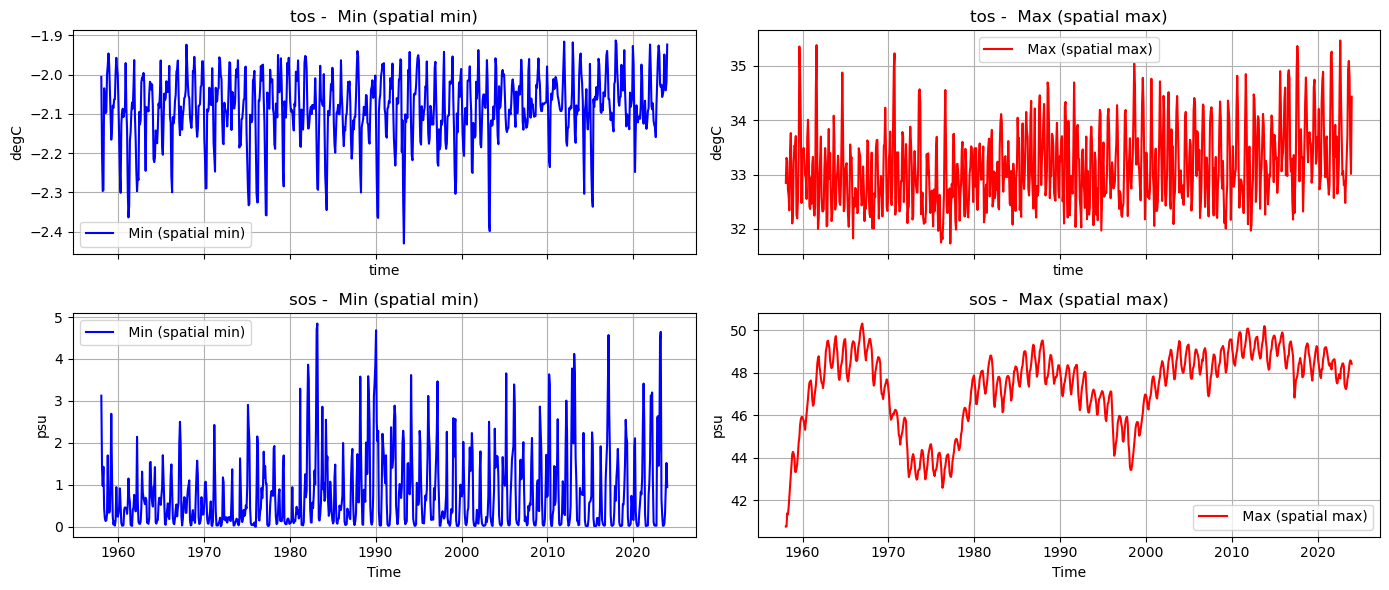

In [8]:
pairs = {}
for v in data:
    if v.endswith("_min"):
        pairs.setdefault(v[:-4], {})["min"] = v
    elif v.endswith("_max"):
        pairs.setdefault(v[:-4], {})["max"] = v

# only keep bases where both min and max actually made it into `data`
complete_pairs = {base: p for base, p in pairs.items() if "min" in p and "max" in p}

incomplete = set(pairs) - set(complete_pairs)
if incomplete:
    print(f"Skipping incomplete pairs (missing min or max): {sorted(incomplete)}")

print(complete_pairs)

n = len(complete_pairs)
fig, axes = plt.subplots(n, 2, figsize=(14, 3*n), sharex=True)
if n == 1:
    axes = axes[None, :]

for i, (base, pair) in enumerate(complete_pairs.items()):
    da_min = data[pair["min"]][pair["min"]]
    da_max = data[pair["max"]][pair["max"]]

    ts_min = da_min.min(dim=("yh", "xh"))
    ts_max = da_max.max(dim=("yh", "xh"))
    units  = da_min.attrs.get("units")

    ts_min.plot(ax=axes[i, 0], color="b", linewidth=1.5, label=" Min (spatial min)")
    axes[i, 0].set_title(f"{base} -  Min (spatial min)")
    axes[i, 0].set_ylabel(units); axes[i, 0].grid(True); axes[i, 0].legend()

    ts_max.plot(ax=axes[i, 1], color="r", linewidth=1.5, label=" Max (spatial max)")
    axes[i, 1].set_title(f"{base} -  Max (spatial max)")
    axes[i, 1].set_ylabel(units); axes[i, 1].grid(True); axes[i, 1].legend()

axes[-1, 0].set_xlabel("Time")
axes[-1, 1].set_xlabel("Time")
plt.tight_layout()

plt.savefig(f"{plotfolder}/timeseries_vars_minmax.png", dpi=150)
mkmd.savefig(plt.gcf(), "Timeseries Extreme Values", "Example figure of ACCESS-OM3 sea surface height (m).", dpi=150)
plt.show()

{'speed': {'max': 'speed_max'}, 'mlotst': {'max': 'mlotst_max'}}


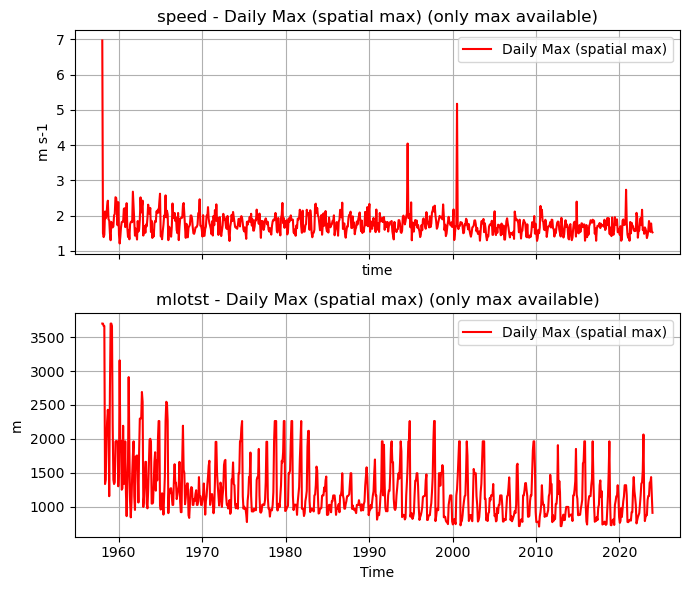

In [9]:
#cb temporary figure for the experiments that have incomplete outputs, so we just make a figure for those (won't be used by mkmd)
incomplete_pairs = {base: p for base, p in pairs.items() if base not in complete_pairs}

print(incomplete_pairs)

n = len(incomplete_pairs)
if n == 0:
    print("No incomplete pairs to plot")
else:
    fig, axes = plt.subplots(n, 1, figsize=(7, 3*n), sharex=True)
    if n == 1:
        axes = [axes]

    for i, (base, pair) in enumerate(incomplete_pairs.items()):
        which = "min" if "min" in pair else "max"
        var_key = pair[which]
        da = data[var_key][var_key]

        ts = da.min(dim=("yh", "xh")) if which == "min" else da.max(dim=("yh", "xh"))
        color = "b" if which == "min" else "r"
        label = "Daily Min (spatial min)" if which == "min" else "Daily Max (spatial max)"
        units = da.attrs.get("units")

        ts.plot(ax=axes[i], color=color, linewidth=1.5, label=label)
        axes[i].set_title(f"{base} - {label} (only {which} available)")
        axes[i].set_ylabel(units); axes[i].grid(True); axes[i].legend()

    axes[-1].set_xlabel("Time")
    plt.tight_layout()

    plt.savefig(f"{plotfolder}/timeseries_vars_incomplete.png", dpi=150)
    plt.show()

In [10]:
client.close()